In [1]:
!pip install -q torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 32.6 MB/s eta 0:00:00


In [2]:
import torch, time, copy, random, itertools
import numpy as np, pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import f1_score
import torch_geometric.transforms as T
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv, SAGEConv, GATConv
from torch_geometric.utils import is_undirected, contains_isolated_nodes

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

##Load and Inspect the dataset

In [3]:
dataset = Planetoid(root='data/Planetoid', name='Cora', transform=T.NormalizeFeatures())
data = dataset[0].to(device)

src, dst = data.edge_index
print("Nodes (papers):", data.num_nodes)
print("Edges (directed count):", data.num_edges, "-> undirected citations:", data.num_edges // 2)
print("Features per node:", data.num_features)
print("Classes:", dataset.num_classes)
print("Class counts:", torch.bincount(data.y).tolist())
print("Train / Val / Test:", data.train_mask.sum().item(), data.val_mask.sum().item(), data.test_mask.sum().item())
print("Undirected:", is_undirected(data.edge_index))
print("Has isolated nodes:", contains_isolated_nodes(data.edge_index, data.num_nodes))
print("Average degree:", round(data.num_edges / data.num_nodes, 2))
print("Avg words per paper:", (data.x > 0).sum(1).float().mean().item())
print("Edge homophily (edges linking same class):", (data.y[src] == data.y[dst]).float().mean().item())

Processing...
Done!


Nodes (papers): 2708
Edges (directed count): 10556 -> undirected citations: 5278
Features per node: 1433
Classes: 7
Class counts: [351, 217, 418, 818, 426, 298, 180]
Train / Val / Test: 140 500 1000
Undirected: True
Has isolated nodes: False
Average degree: 3.9
Avg words per paper: 18.174297332763672
Edge homophily (edges linking same class): 0.8099659085273743


## The models

In [4]:
class Net(nn.Module):
    def __init__(self, kind, in_dim, hidden, out_dim, num_layers=2, dropout=0.5, heads=8):
        super().__init__()
        self.kind, self.dropout = kind, dropout
        self.layers = nn.ModuleList()
        for i in range(num_layers):
            last = (i == num_layers - 1)
            in_c = in_dim if i == 0 else hidden
            out_c = out_dim if last else hidden
            if kind == 'MLP':
                self.layers.append(nn.Linear(in_c, out_c))
            elif kind == 'GCN':
                self.layers.append(GCNConv(in_c, out_c))
            elif kind == 'SAGE':
                self.layers.append(SAGEConv(in_c, out_c))
            elif kind == 'GAT':
                if last:
                    self.layers.append(GATConv(in_c, out_c, heads=1))
                else:
                    self.layers.append(GATConv(in_c, hidden // heads, heads=heads))

    def forward(self, x, edge_index, return_emb=False):
        for i, layer in enumerate(self.layers):
            last = (i == len(self.layers) - 1)
            x = F.dropout(x, p=self.dropout, training=self.training)
            if last and return_emb:
                return x                      # embedding = input of the last layer
            x = layer(x) if self.kind == 'MLP' else layer(x, edge_index)
            if not last:
                x = F.relu(x)
        return x

def count_params(model):
    return sum(p.numel() for p in model.parameters())

##Training loop and evaluation

In [5]:
@torch.no_grad()
def evaluate(model, data, edge_index, mask):
    model.eval()
    pred = model(data.x, edge_index).argmax(dim=1)
    y_true = data.y[mask].cpu().numpy()
    y_pred = pred[mask].cpu().numpy()
    acc = (y_true == y_pred).mean()
    f1 = f1_score(y_true, y_pred, average='macro')
    return acc, f1

def run(kind, cfg, edge_index, seed, num_layers=2, epochs=200, patience=50):
    """Train one model. Keeps the checkpoint with the best VALIDATION accuracy."""
    set_seed(seed)
    model = Net(kind, data.num_features, cfg['hidden'], dataset.num_classes,
                num_layers, cfg['dropout']).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=5e-4)

    best_val, best_state, bad = -1, None, 0
    start = time.time()
    for epoch in range(epochs):
        model.train()
        opt.zero_grad()
        out = model(data.x, edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        opt.step()

        val_acc, _ = evaluate(model, data, edge_index, data.val_mask)
        if val_acc > best_val:
            best_val, best_state, bad = val_acc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    train_time = time.time() - start
    model.load_state_dict(best_state)       # go back to the best checkpoint
    return model, best_val, train_time

##Hyperparameter tuning (same budget for every model)

In [6]:
kinds = ['MLP', 'GCN', 'SAGE', 'GAT']
grid = list(itertools.product([0.01, 0.005], [16, 64], [0.5, 0.7]))   # lr, hidden, dropout

best_cfg, tuning_rows = {}, []
for kind in kinds:
    best_val = -1
    for lr, hidden, dropout in grid:
        cfg = {'lr': lr, 'hidden': hidden, 'dropout': dropout}
        _, val, _ = run(kind, cfg, data.edge_index, seed=0)
        tuning_rows.append({'model': kind, **cfg, 'val_acc': round(val, 4)})
        if val > best_val:
            best_val, best_cfg[kind] = val, cfg

print(pd.DataFrame(tuning_rows).to_string(index=False))
print(best_cfg)

model    lr  hidden  dropout  val_acc
  MLP 0.010      16      0.5    0.604
  MLP 0.010      16      0.7    0.588
  MLP 0.010      64      0.5    0.604
  MLP 0.010      64      0.7    0.606
  MLP 0.005      16      0.5    0.582
  MLP 0.005      16      0.7    0.598
  MLP 0.005      64      0.5    0.608
  MLP 0.005      64      0.7    0.618
  GCN 0.010      16      0.5    0.802
  GCN 0.010      16      0.7    0.810
  GCN 0.010      64      0.5    0.806
  GCN 0.010      64      0.7    0.818
  GCN 0.005      16      0.5    0.796
  GCN 0.005      16      0.7    0.764
  GCN 0.005      64      0.5    0.810
  GCN 0.005      64      0.7    0.812
 SAGE 0.010      16      0.5    0.780
 SAGE 0.010      16      0.7    0.810
 SAGE 0.010      64      0.5    0.798
 SAGE 0.010      64      0.7    0.808
 SAGE 0.005      16      0.5    0.788
 SAGE 0.005      16      0.7    0.800
 SAGE 0.005      64      0.5    0.798
 SAGE 0.005      64      0.7    0.812
  GAT 0.010      16      0.5    0.794
  GAT 0.010 

##Final results

In [7]:
rows, saved = [], {}
for kind in kinds:
    for seed in [0, 1, 2]:
        model, val, t = run(kind, best_cfg[kind], data.edge_index, seed)
        acc, f1 = evaluate(model, data, data.edge_index, data.test_mask)
        rows.append({'model': kind, 'seed': seed, 'val_acc': val, 'test_acc': acc,
                     'test_f1': f1, 'train_time_s': t, 'params': count_params(model)})
        if seed == 0:
            saved[kind] = model       # keep for error analysis later

df = pd.DataFrame(rows)
summary = df.groupby('model')[['test_acc', 'test_f1', 'train_time_s', 'params']].agg(['mean', 'std']).round(4)
print(summary)

      test_acc         test_f1         train_time_s            params     
          mean     std    mean     std         mean     std      mean  std
model                                                                     
GAT     0.8083  0.0163  0.8038  0.0122       0.9261  0.3147   92373.0  0.0
GCN     0.8300  0.0070  0.8159  0.0077       0.7657  0.0326   92231.0  0.0
MLP     0.6007  0.0146  0.5821  0.0137       0.6867  0.0790   92231.0  0.0
SAGE    0.8160  0.0035  0.8073  0.0029       1.0144  0.2434  184391.0  0.0


Depth experiment (accuracy and embedding similarity)

             test_acc         similarity        
                 mean     std       mean     std
model layers                                    
GAT   2        0.8083  0.0163     0.8685  0.0408
      4        0.7907  0.0084     0.5839  0.0120
      8        0.3837  0.1120     0.9080  0.1593
      16       0.3190  0.0000     1.0000  0.0000
GCN   2        0.8300  0.0070     0.8493  0.0185
      4        0.7887  0.0124     0.5986  0.0109
      8        0.3090  0.1722     0.8536  0.2499
      16       0.2443  0.0541     0.9954  0.0015
SAGE  2        0.8160  0.0035     0.7757  0.0455
      4        0.7873  0.0071     0.5798  0.0114
      8        0.2623  0.0981     1.0000  0.0000
      16       0.2057  0.0981     1.0000  0.0000


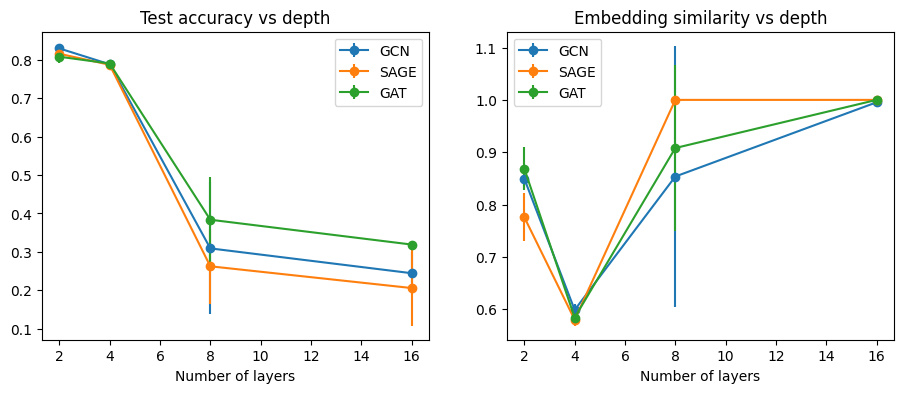

In [9]:
@torch.no_grad()
def embedding_similarity(model):
    model.eval()
    emb = model(data.x, data.edge_index, return_emb=True)
    emb = F.normalize(emb, dim=1)
    sim = emb @ emb.T
    n = emb.size(0)
    return ((sim.sum() - sim.diag().sum()) / (n * (n - 1))).item()

depth_rows = []
for kind in ['GCN', 'SAGE', 'GAT']:
    for L in [2, 4, 8, 16]:
        for seed in [0, 1, 2]:
            model, val, _ = run(kind, best_cfg[kind], data.edge_index, seed, num_layers=L)
            acc, _ = evaluate(model, data, data.edge_index, data.test_mask)
            depth_rows.append({'model': kind, 'layers': L, 'test_acc': acc,
                               'similarity': embedding_similarity(model)})

depth_df = pd.DataFrame(depth_rows)
depth_summary = depth_df.groupby(['model', 'layers']).agg(['mean', 'std']).round(4)
print(depth_summary)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for kind in ['GCN', 'SAGE', 'GAT']:
    d = depth_df[depth_df.model == kind].groupby('layers')[['test_acc', 'similarity']].agg(['mean', 'std'])
    ax[0].errorbar(d.index, d[('test_acc', 'mean')], d[('test_acc', 'std')], marker='o', label=kind)
    ax[1].errorbar(d.index, d[('similarity', 'mean')], d[('similarity', 'std')], marker='o', label=kind)
ax[0].set_title('Test accuracy vs depth')
ax[1].set_title('Embedding similarity vs depth')
for a in ax:
    a.set_xlabel('Number of layers')
    a.legend()
plt.show()

##Edge removal experiment

                 mean     std
model removed                
GAT   0.0      0.8083  0.0163
      0.2      0.7943  0.0160
      0.4      0.7713  0.0090
      0.6      0.7387  0.0074
      0.8      0.6660  0.0131
      1.0      0.5943  0.0055
GCN   0.0      0.8300  0.0070
      0.2      0.8107  0.0021
      0.4      0.7800  0.0036
      0.6      0.7423  0.0031
      0.8      0.6877  0.0222
      1.0      0.5980  0.0066
MLP   0.0      0.6007  0.0146
      0.2      0.6007  0.0146
      0.4      0.6007  0.0146
      0.6      0.6007  0.0146
      0.8      0.6007  0.0146
      1.0      0.6007  0.0146
SAGE  0.0      0.8160  0.0035
      0.2      0.7853  0.0045
      0.4      0.7000  0.0272
      0.6      0.6550  0.0053
      0.8      0.5797  0.0182
      1.0      0.5797  0.0142


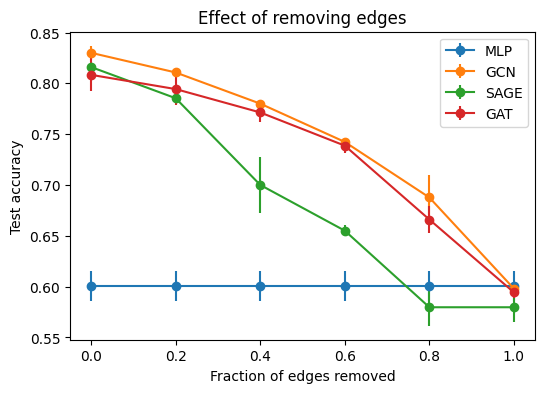

In [10]:
def drop_edges(edge_index, p, seed):
    """Remove a fraction p of the undirected edges."""
    g = torch.Generator().manual_seed(seed)
    ei = edge_index.cpu()
    undirected = ei[:, ei[0] < ei[1]]                  # each edge once
    keep = torch.rand(undirected.size(1), generator=g) >= p
    kept = undirected[:, keep]
    return torch.cat([kept, kept.flip(0)], dim=1).to(device)   # add both directions back

edge_rows = []
for kind in kinds:
    for p in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]:
        for seed in [0, 1, 2]:
            ei = drop_edges(data.edge_index, p, seed)
            model, val, _ = run(kind, best_cfg[kind], ei, seed)
            acc, _ = evaluate(model, data, ei, data.test_mask)
            edge_rows.append({'model': kind, 'removed': p, 'test_acc': acc})

edge_df = pd.DataFrame(edge_rows)
print(edge_df.groupby(['model', 'removed']).test_acc.agg(['mean', 'std']).round(4))

plt.figure(figsize=(6, 4))
for kind in kinds:
    d = edge_df[edge_df.model == kind].groupby('removed').test_acc.agg(['mean', 'std'])
    plt.errorbar(d.index, d['mean'], d['std'], marker='o', label=kind)
plt.xlabel('Fraction of edges removed'); plt.ylabel('Test accuracy')
plt.title('Effect of removing edges'); plt.legend(); plt.show()

Error analysis

In [11]:
# best GNN chosen by VALIDATION accuracy
best_gnn = df[df.model != 'MLP'].groupby('model').val_acc.mean().idxmax()
print("Best GNN by validation:", best_gnn)
gnn, mlp = saved[best_gnn], saved['MLP']

gnn.eval(); mlp.eval()
with torch.no_grad():
    g_prob = F.softmax(gnn(data.x, data.edge_index), dim=1)
    g_pred = g_prob.argmax(1)
    m_pred = mlp(data.x, data.edge_index).argmax(1)

test_idx = data.test_mask.nonzero().squeeze()
wrong = test_idx[g_pred[test_idx] != data.y[test_idx]]
print("Wrong test predictions:", len(wrong))

random.seed(0)
chosen = random.sample(wrong.tolist(), 8)
ei = data.edge_index.cpu()
y = data.y.cpu()

rows = []
for n in chosen:
    nbrs = ei[1][ei[0] == n]
    nbr_labels = y[nbrs].tolist()
    same = np.mean([l == y[n].item() for l in nbr_labels]) if nbr_labels else float('nan')
    rows.append({
        'node': n, 'true': y[n].item(), 'gnn_pred': g_pred[n].item(),
        'confidence': round(g_prob[n].max().item(), 2),
        'degree': len(nbrs),
        'neighbour_labels': dict(Counter(nbr_labels)),
        'frac_neighbours_same_class': round(same, 2),
        'words_in_paper': int((data.x[n] > 0).sum().item()),
        'mlp_correct': bool(m_pred[n] == data.y[n]),
    })
print(pd.DataFrame(rows).to_string(index=False))

Best GNN by validation: GAT
Wrong test predictions: 186
 node  true  gnn_pred  confidence  degree   neighbour_labels  frac_neighbours_same_class  words_in_paper  mlp_correct
 2293     0         6        0.28       3       {6: 1, 0: 2}                        0.67              18         True
 2332     0         4        0.26       3       {0: 2, 4: 1}                        0.67              18         True
 1803     0         6        0.39       4 {6: 1, 0: 2, 2: 1}                        0.50              22         True
 2102     5         0        0.26       3 {5: 1, 0: 1, 4: 1}                        0.33              24        False
 2425     3         0        0.22       5       {0: 3, 3: 2}                        0.40              19        False
 2405     3         5        0.30       7             {5: 7}                        0.00              18        False
 2320     3         0        0.20       2       {3: 1, 0: 1}                        0.50              18         True
